TechBazaar: E-commerce Sales Data Cleaning & EDA

Importing Libraries

In [403]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sea

Importing Data

In [404]:
customer=pd.read_csv("messy_customers.csv")
order_items=pd.read_csv("messy_order_items.csv")
orders=pd.read_csv("messy_orders.csv")
products=pd.read_csv("messy_products.csv",encoding="latin1")


Data Exploration

In [405]:
customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customer_id    520 non-null    str  
 1   customer_name  492 non-null    str  
 2   city           479 non-null    str  
 3   signup_date    520 non-null    str  
dtypes: str(4)
memory usage: 16.4 KB


In [406]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 2050 entries, 0 to 2049
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_item_id  2050 non-null   int64  
 1   order_id       2050 non-null   str    
 2   product_id     2050 non-null   str    
 3   quantity       1732 non-null   float64
 4   unit_price     1039 non-null   float64
dtypes: float64(2), int64(1), str(2)
memory usage: 80.2 KB


In [407]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 1240 entries, 0 to 1239
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   order_id        1240 non-null   str  
 1   customer_id     1240 non-null   str  
 2   order_date      1240 non-null   str  
 3   payment_method  1095 non-null   str  
dtypes: str(4)
memory usage: 38.9 KB


In [408]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    90 non-null     str    
 1   product_name  90 non-null     str    
 2   category      90 non-null     str    
 3   base_price    33 non-null     float64
dtypes: float64(1), str(3)
memory usage: 2.9 KB


DATA CLEANING

Customers

In [409]:
customer.isnull().sum()

customer_id       0
customer_name    28
city             41
signup_date       0
dtype: int64

In [410]:
customer["customer_name"]=customer["customer_name"].fillna("Unknown")
customer["city"]=customer["city"].fillna("Unknown")

In [411]:
customer["city"].value_counts()

city
Hyderabad    54
delhi        53
Mumbai       51
Pune         49
Kolkata      45
DELHI        43
Bangalore    43
Unknown      41
mumbai       40
Delhi        38
Chennai      35
Bengaluru    28
Name: count, dtype: int64

In [412]:
customer["city"]=customer["city"].replace({'delhi':'Delhi'})
customer["city"]=customer["city"].replace({'DELHI':'Delhi'})
customer["city"]=customer["city"].replace({'Bengaluru':'Bangalore'})
customer["city"]=customer["city"].str.capitalize()

In [413]:
customer["city"].value_counts()

city
Delhi        134
Mumbai        91
Bangalore     71
Hyderabad     54
Pune          49
Kolkata       45
Unknown       41
Chennai       35
Name: count, dtype: int64

In [414]:
customer.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
515     True
516     True
517     True
518     True
519     True
Length: 520, dtype: bool

In [415]:
customer.drop_duplicates(inplace=True)

In [416]:
customer["signup_date"]

0      2024-02-09
1      2025-04-20
2      2024-08-19
3      2023-08-08
4      2024-03-04
          ...    
495    2023-01-01
496    2023-01-26
497    2023-06-13
498    2023-01-13
499    2023-07-21
Name: signup_date, Length: 500, dtype: str

In [417]:
customer['signup_date']=pd.to_datetime(customer['signup_date'],format="mixed")

Orders

In [418]:
orders.isnull().sum()

order_id            0
customer_id         0
order_date          0
payment_method    145
dtype: int64

In [419]:
orders["payment_method"]= orders["payment_method"].fillna("Unknown")

In [420]:
orders["payment_method"].value_counts()

payment_method
Credit Card         171
Cash                170
UPI                 163
upi                 156
credit card         151
Cash on Delivery    148
Unknown             145
Debit Card          136
Name: count, dtype: int64

In [421]:
orders["payment_method"] = orders["payment_method"].str.lower()
orders["payment_method"] = orders["payment_method"].replace({"upi": "UPI",
                                                             "credit card": "Credit Card",
                                                             "debit card": "Debit Card",
                                                             "cash": "Cash on Delivery",
                                                             "cash on delivery": "Cash on Delivery",
                                                             "unknown": "Unknown"})

In [422]:
orders.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
1235     True
1236     True
1237     True
1238     True
1239     True
Length: 1240, dtype: bool

In [423]:
orders.drop_duplicates(inplace=True)

In [424]:
orders["order_date"]=pd.to_datetime(orders["order_date"],format="mixed")

Order Items

In [425]:
order_items.isnull().sum()

order_item_id       0
order_id            0
product_id          0
quantity          318
unit_price       1011
dtype: int64

In [426]:
order_items["quantity"]=order_items["quantity"].fillna(1)
order_items["quantity"]=order_items["quantity"].replace({"0":"1"})

In [427]:
avg=order_items["unit_price"].mean()
print(round(avg))

44956


In [428]:
order_items["unit_price"]=order_items["unit_price"].fillna(44956)

In [429]:
order_items.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
2045     True
2046     True
2047     True
2048     True
2049     True
Length: 2050, dtype: bool

In [430]:
order_items.drop_duplicates(inplace=True)

Products


In [431]:
products.isnull().sum()

product_id       0
product_name     0
category         0
base_price      57
dtype: int64

In [432]:
mean=products["base_price"].mean()
print(round(mean))

45047


In [433]:
products["base_price"]=products["base_price"].fillna(45057)

In [434]:
products["category"].value_counts()

category
smart phone    17
Tablet         16
laptop         13
Accessory      12
Smartphone     11
Accessories    11
tablet          5
Laptop          5
Name: count, dtype: int64

In [435]:
products["category"]=products["category"].str.title()
products["category"]=products["category"].replace({"Smart Phone":"Smartphone"})
products["category"]=products["category"].replace({"Accessory":"Accessories"})

In [436]:
products.duplicated()

0     False
1     False
2     False
3     False
4     False
      ...  
85     True
86     True
87     True
88     True
89     True
Length: 90, dtype: bool

In [437]:
products.drop_duplicates(inplace=True)

Data Transformation

In [438]:
#Orders["order_date"]

orders["Month"]=orders["order_date"].dt.month_name()
orders["Month_no"]=orders["order_date"].dt.month
orders["Year"]=orders["order_date"].dt.year
orders["Quarter"]=orders["order_date"].dt.quarter

In [439]:
#customer["signup_date"]

customer["Month"]=customer["signup_date"].dt.month_name()
customer["Year"]=customer["signup_date"].dt.year
customer["Quarter"]=customer["signup_date"].dt.quarter

In [440]:
#pd.merge(customer,orders,on='customer_id',how="right")

Insights

In [441]:
#1--Amount

order_items["Amount"]=order_items["quantity"] * order_items["unit_price"]

In [442]:
mix=products.merge(order_items,on="product_id")

In [443]:
mix

,product_id,product_name,category,base_price,order_item_id,order_id,quantity,unit_price,Amount
0,P001,Lenovo IdeaPad,Tablet,28151.0,228,O00862,1.0,30940.0,30940.0
1,P001,Lenovo IdeaPad,Tablet,28151.0,427,O00610,4.0,44956.0,179824.0
2,P001,Lenovo IdeaPad,Tablet,28151.0,618,O00343,4.0,44956.0,179824.0
3,P001,Lenovo IdeaPad,Tablet,28151.0,634,O00485,1.0,44956.0,44956.0
4,P001,Lenovo IdeaPad,Tablet,28151.0,662,O01127,1.0,34936.0,34936.0
...,...,...,...,...,...,...,...,...,...
1995,P080,OnePlus,Laptop,82478.0,1662,O01122,1.0,44956.0,44956.0
1996,P080,OnePlus,Laptop,82478.0,1695,O00412,2.0,44956.0,89912.0
1997,P080,OnePlus,Laptop,82478.0,1814,O00575,0.0,80491.0,0.0
1998,P080,OnePlus,Laptop,82478.0,1872,O00288,2.0,44956.0,89912.0


In [444]:
#2--Total Revenue

total_revenue=order_items["quantity"] * order_items["unit_price"]
print(f"The total revenue {sum(total_revenue)}")

The total revenue 165732260.0


In [445]:
#3--Top category based on quantity

top_products=mix.groupby("category")["quantity"].sum()
print(top_products)

category
Accessories     938.0
Laptop          708.0
Smartphone     1187.0
Tablet          852.0
Name: quantity, dtype: float64


In [446]:
#4--Top category based on revenue

top_category=mix.groupby("category")["Amount"].sum()
print(top_category)

category
Accessories    42727294.0
Laptop         31231663.0
Smartphone     52720196.0
Tablet         39053107.0
Name: Amount, dtype: float64


In [447]:
#5--Payment method used by customer the most

Payment_method=orders.groupby("payment_method")["order_id"].count().sort_values()
print(Payment_method)

payment_method
Debit Card          134
Unknown             141
Cash on Delivery    303
Credit Card         309
UPI                 313
Name: order_id, dtype: int64


In [448]:
Data=customer.merge(orders,on="customer_id").merge(order_items,on="order_id").merge(products,on="product_id")

In [449]:
Data

,customer_id,customer_name,city,signup_date,Month_x,Year_x,Quarter_x,order_id,order_date,payment_method,...,Year_y,Quarter_y,order_item_id,product_id,quantity,unit_price,Amount,product_name,category,base_price
0,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,124,P033,2.0,44956.0,89912.0,Wireless Mouse,Laptop,47453.0
1,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,235,P070,4.0,35845.0,143380.0,iPad Air,Tablet,45057.0
2,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,397,P064,3.0,44956.0,134868.0,Lenovo IdeaPad,Accessories,81129.0
3,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,719,P029,4.0,44956.0,179824.0,Samsung Galaxy,Accessories,45057.0
4,C0001,Customer_1,Delhi,2024-02-09,February,2024,1,O00309,2024-02-27,Debit Card,...,2024,1,1206,P060,0.0,28975.0,0.0,USB Hub,Laptop,45057.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O00489,2025-11-01,UPI,...,2025,4,1488,P043,2.0,72197.0,144394.0,USB Hub,Accessories,45057.0
1996,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O00789,2024-10-14,UPI,...,2024,4,53,P028,4.0,41806.0,167224.0,Samsung Galaxy,Tablet,45057.0
1997,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O01049,2024-08-30,Unknown,...,2024,3,256,P042,1.0,80536.0,80536.0,HP Pavilion,Laptop,45057.0
1998,C0498,Customer_498,Mumbai,2023-06-13,June,2023,2,O01049,2024-08-30,Unknown,...,2024,3,1001,P072,1.0,16284.0,16284.0,Dell Inspiron,Tablet,45057.0


In [450]:
#6--Total revenue by year

yearly_rev=Data.groupby("Year_y")["Amount"].sum()
print(yearly_rev)

Year_y
2024    121910425.0
2025     43821835.0
Name: Amount, dtype: float64


In [451]:
#7--Total revenue by month

monthly_rev=Data.groupby("Month_y")["Amount"].sum().sort_values()
print(monthly_rev)

Month_y
August        8266607.0
September     8683288.0
November      9578634.0
October       9641951.0
July         10541290.0
December     11318535.0
June         11401969.0
May          14863265.0
February     17592219.0
March        20218531.0
April        21199618.0
January      22426353.0
Name: Amount, dtype: float64


In [452]:
#8--Total revenue in quarters

quarterly_rev=Data.groupby("Quarter_y")["Amount"].sum().sort_values()
print(quarterly_rev)

Quarter_y
3    27491185.0
4    30539120.0
2    47464852.0
1    60237103.0
Name: Amount, dtype: float64


In [453]:
#9--Top city by revenue

City_wise_rev=Data.groupby("city")["Amount"].sum().sort_values()
print(City_wise_rev)

city
Chennai      10032253.0
Kolkata      11539029.0
Unknown      13515317.0
Pune         14258962.0
Bangalore    20171418.0
Hyderabad    22691019.0
Mumbai       26877981.0
Delhi        46646281.0
Name: Amount, dtype: float64


Report

In [454]:
orders

,order_id,customer_id,order_date,payment_method,Month,Month_no,Year,Quarter
0,O00001,C0058,2024-09-05,Cash on Delivery,September,9,2024,3
1,O00002,C0410,2024-02-01,UPI,February,2,2024,1
2,O00003,C0429,2025-04-13,Cash on Delivery,April,4,2025,2
3,O00004,C0272,2024-02-25,Debit Card,February,2,2024,1
4,O00005,C0411,2025-04-26,Credit Card,April,4,2025,2
...,...,...,...,...,...,...,...,...
1195,O01196,C0392,2024-09-14,Unknown,September,9,2024,3
1196,O01197,C0260,2024-04-09,Unknown,April,4,2024,2
1197,O01198,C0459,2024-05-29,Unknown,May,5,2024,2
1198,O01199,C0130,2024-03-13,Unknown,March,3,2024,1


Text(0.5, 1.0, 'Total revenue per payment method')

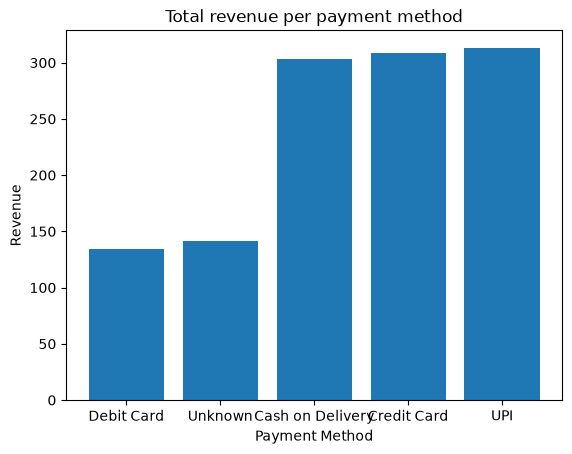

In [455]:
#Paymentmethod graph

plt.bar(Payment_method.index,Payment_method.values)
plt.xlabel("Payment Method")
plt.ylabel("Revenue")
plt.title('Total revenue per payment method')

<Axes: xlabel='category', ylabel='quantity'>

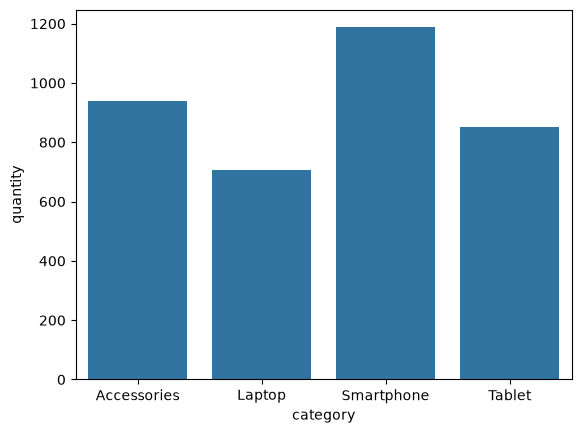

In [456]:
#Top Products graph

sea.barplot(top_products)

Text(0.5, 1.0, 'Quarterly Revenue')

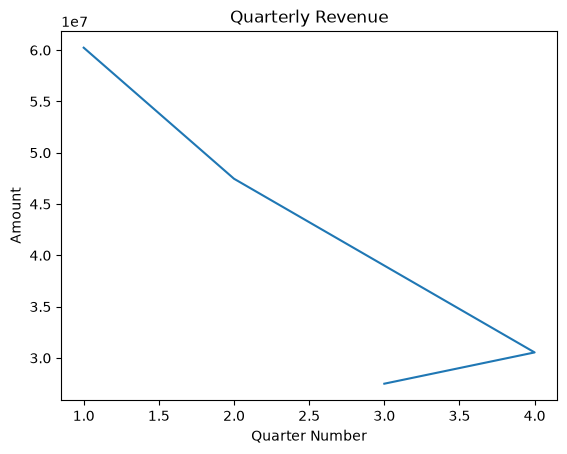

In [457]:
#Quarterly Revenue

plt.plot(quarterly_rev.index,quarterly_rev.values)
plt.xlabel("Quarter Number")
plt.ylabel("Amount")
plt.title("Quarterly Revenue")

Text(0.5, 1.0, 'Monthly Revenue')

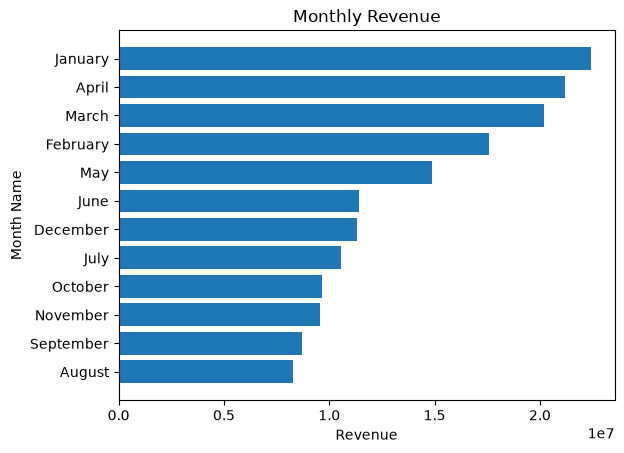

In [458]:
#Montly Revenue

plt.barh(monthly_rev.index,monthly_rev.values)
plt.ylabel("Month Name")
plt.xlabel("Revenue")
plt.title("Monthly Revenue")

Text(0.5, 1.0, 'Top Product Quantity sold')

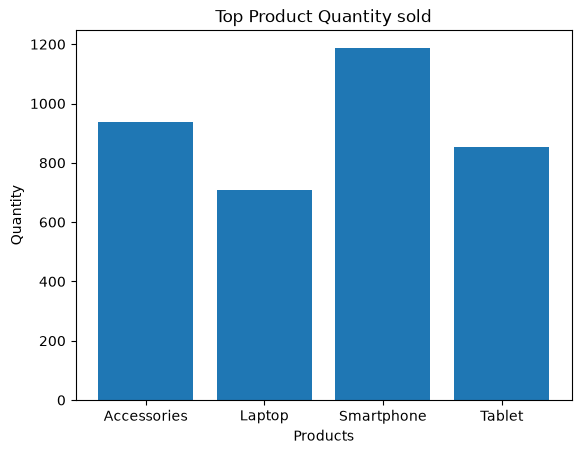

In [459]:
#Top products sold

plt.bar(top_products.index,top_products.values)
plt.xlabel("Products")
plt.ylabel("Quantity")
plt.title("Top Product Quantity sold")

Text(0.5, 1.0, 'City Wise Revenue Generated')

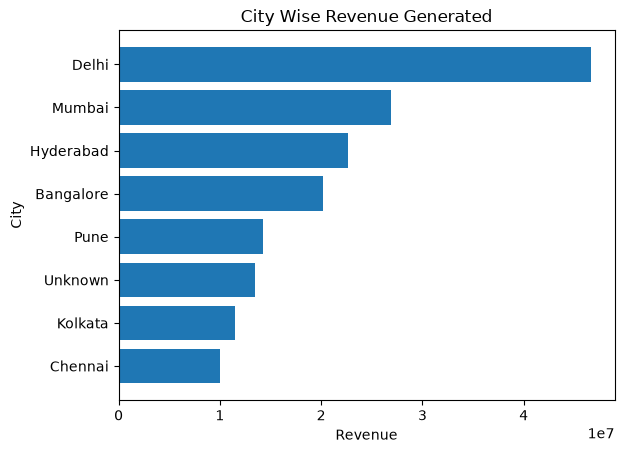

In [460]:
#Revenue generated by per city

plt.barh(City_wise_rev.index,City_wise_rev.values)
plt.xlabel("Revenue")
plt.ylabel("City")
plt.title("City Wise Revenue Generated")

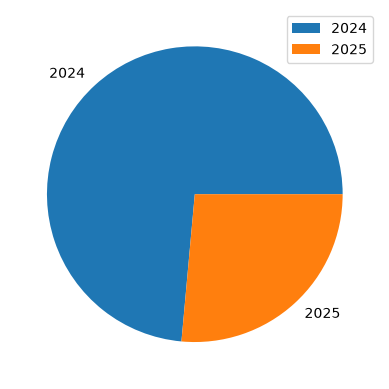

In [461]:
#Yearly Revenue

plt.pie(yearly_rev,labels=yearly_rev.index)
plt.legend()
plt.show()